# Seed diversity and batch diversity vs active-learning performance

Using the new metrics logged during the AL runs:

- **Initial Seed Shannon Entropy** / **Initial Seed Mean Levenshtein** - diversity of the starting 20-peptide pool. Do more diverse seeds lead to better campaigns?
- **Batch Mean Levenshtein** / **Batch Embedding Variance** - how diverse each acquired batch is, compared across greedy / mixed / UCB strategies.

Reads the AL `df_all.csv`. All metrics are in its long format (`Metric`/`Value`), tagged by `Representation` and `Acquisition`.

In [1]:
import sys, os
try:
    import analysis_common as ac
except ModuleNotFoundError:
    sys.path.insert(0, os.getcwd()); import analysis_common as ac
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
mpl.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('repo root:', ac.ROOT)


repo root: /Users/leoan/Documents/GitHub/SCARSE-repro


In [2]:
df = ac.load_al_results()
if df is not None:
    print('metrics present:')
    for m in sorted(df['Metric'].dropna().unique()):
        print('  ', m)
    print('representations:', df['Representation'].dropna().unique())
    print('acquisitions:', df['Acquisition'].dropna().unique())


metrics present:
   Batch Embedding Variance
   Batch Mean Levenshtein
   Initial Seed Mean Levenshtein
   Initial Seed Shannon Entropy
   Norm. Target Mean (Cumulative)
   Norm. Target Mean (Round)
   Remaining Top10 Quality
   Top 10% peptides selected (%)
representations: ['esm' 'morgan' 'ngram' 'physchem']
acquisitions: ['greedy' 'mixed' 'ucb']


In [3]:
# Endpoint (final) AL performance per (dataset, seed): the Top 10% selected (%)
# at the largest Num_samples, expressed as x-random, matching the main analysis.
def endpoint_perf(df, representation='esm', acquisition='greedy'):
    sub = df[(df['Representation'] == representation) &
             (df['Acquisition'] == acquisition) &
             (df['Metric'] == 'Top 10% peptides selected (%)')].copy()
    if sub.empty:
        return pd.DataFrame()
    sub['Value'] = pd.to_numeric(sub['Value'], errors='coerce')
    idx = sub.groupby(['Dataset', 'Seed'])['Num_samples'].idxmax()
    end = sub.loc[idx, ['Dataset', 'Seed', 'Value']].rename(columns={'Value': 'endpoint'})
    return end


saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/entropy_vs_endpoint.png
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/entropy_vs_endpoint.pdf


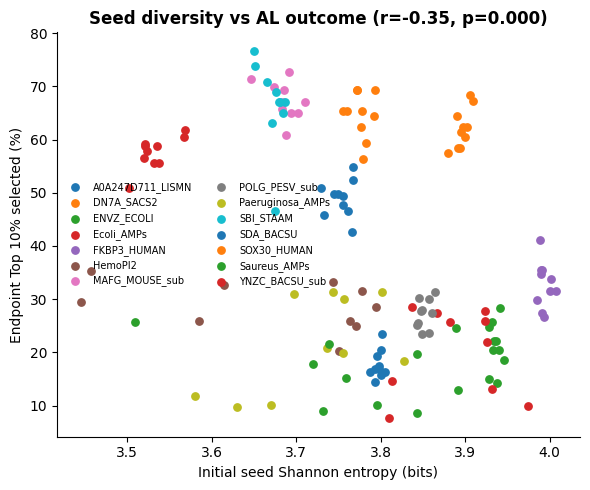

In [4]:
# Correlate initial-seed Shannon entropy with endpoint performance (SCARSE greedy).
from scipy.stats import pearsonr
if df is not None:
    ent = df[df['Metric'] == 'Initial Seed Shannon Entropy'][['Dataset','Seed','Value']]
    ent = ent.rename(columns={'Value': 'entropy'}).drop_duplicates(['Dataset','Seed'])
    ent['entropy'] = pd.to_numeric(ent['entropy'], errors='coerce')
    end = endpoint_perf(df, 'esm', 'greedy')
    merged = ent.merge(end, on=['Dataset','Seed']).dropna()
    if len(merged) >= 3:
        r, p = pearsonr(merged['entropy'], merged['endpoint'])
        fig, ax = plt.subplots(figsize=(6, 5))
        for ds, g in merged.groupby('Dataset'):
            ax.scatter(g['entropy'], g['endpoint'], s=28, label=ds)
        ax.set_xlabel('Initial seed Shannon entropy (bits)')
        ax.set_ylabel('Endpoint Top 10% selected (%)')
        ax.set_title(f'Seed diversity vs AL outcome (r={r:.2f}, p={p:.3f})', fontweight='bold')
        ax.legend(fontsize=7, frameon=False, ncol=2)
        fig.tight_layout(); ac.savefig(fig, 'entropy_vs_endpoint'); plt.show()
    else:
        print('Not enough rows yet - run the updated AL simulation to log entropy.')


saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/batch_batch_mean_levenshtein.png
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/batch_batch_mean_levenshtein.pdf


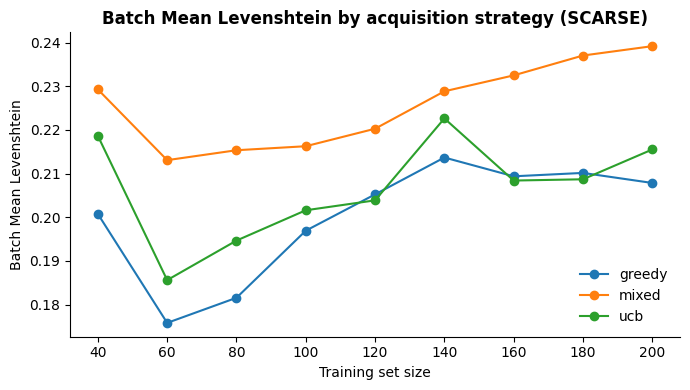

saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/batch_batch_embedding_variance.png
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/batch_batch_embedding_variance.pdf


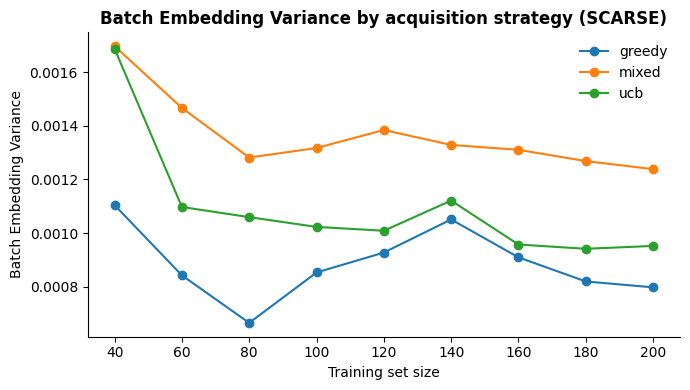

In [5]:
# Batch diversity by strategy: mean Levenshtein and embedding variance per round.
if df is not None:
    for metric in ['Batch Mean Levenshtein', 'Batch Embedding Variance']:
        sub = df[(df['Metric'] == metric) & (df['Representation'] == 'esm')].copy()
        if sub.empty:
            print(f'No rows for {metric} yet (run the updated AL simulation).'); continue
        sub['Value'] = pd.to_numeric(sub['Value'], errors='coerce')
        agg = sub.groupby(['Acquisition', 'Num_samples'])['Value'].mean().reset_index()
        fig, ax = plt.subplots(figsize=(7, 4))
        for acq, g in agg.groupby('Acquisition'):
            ax.plot(g['Num_samples'], g['Value'], 'o-', label=acq)
        ax.set_xlabel('Training set size'); ax.set_ylabel(metric)
        ax.set_title(f'{metric} by acquisition strategy (SCARSE)', fontweight='bold')
        ax.legend(frameon=False)
        fig.tight_layout(); ac.savefig(fig, 'batch_' + metric.lower().replace(' ', '_')); plt.show()
